In [1]:
import time
import matplotlib.pyplot as plt
from IPython.display import display

import threading

from src.monitor import run_monitor
from src.send import one_request

import pandas as pd
import matplotlib.pyplot as plt

# Testing sending one request

In [2]:
r = one_request("Say hi", max_tokens=64)
print(r["status"], "ttft:", r["ttft"], "ttft_content:", r["ttft_content"],
      "chunks:", r["chunks"])
print("ANSWER:", r["response_text"][:200])
print("THINKING:", r["reasoning_text"][:200])

ok ttft: 0.3207428455352783 ttft_content: 0.3207437992095947 chunks: 32
ANSWER: Hello! How can I help you today? 😊 What's on your mind? 🌟✨🚀🌍🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱🌱
THINKING: 


# Test monitoring one request

In [11]:
prompt = "Find the three most-starred Python repos for web scraping, compare their licenses, and recommend one for a commercial project."

In [16]:
# Setup Monitoring
monitored_samples = []
stop_event = threading.Event()
monitor_thread = threading.Thread(target=run_monitor, args=(stop_event, monitored_samples), daemon=True)

# Start Monitoring
monitor_thread.start()           
time.sleep(1)

request_results = {}
try:
    # POST Request
    request_results = one_request(prompt, max_tokens=64)
finally:
    time.sleep(1)
    stop_event.set() # kill monitoring
    monitor_thread.join()
    print(request_results['status'])

ok


# Process Results

### Monitoring Results

In [17]:
df = pd.DataFrame(monitored_samples)

# elapsed seconds since first sample
df["t_elapsed"] = df["t_mono"] - df["t_mono"].iloc[0]

# bytes -> GB
for c in ["rss", "uss", "vms", "sys_avail", "swap_used"]:
    df[c + "_gb"] = df[c] / 1024**3

df

,t_wall,t_mono,rss,uss,vms,sys_avail,swap_used,cpu_pct,t_elapsed,rss_gb,uss_gb,vms_gb,sys_avail_gb,swap_used_gb
0,1.792886e+09,14914.567086,2674552832,2671480832,78037344256,9962496000,0,0.0,0.000000,2.490871,2.48801,72.67794,9.278297,0.0
1,1.792886e+09,14914.779291,2674552832,2671480832,78037344256,9962479616,0,0.0,0.212205,2.490871,2.48801,72.67794,9.278282,0.0
2,1.792886e+09,14914.991256,2674552832,2671480832,78037344256,9962496000,0,0.0,0.424170,2.490871,2.48801,72.67794,9.278297,0.0
3,1.792886e+09,14915.203978,2674552832,2671480832,78037344256,9962496000,0,0.0,0.636892,2.490871,2.48801,72.67794,9.278297,0.0
4,1.792886e+09,14915.416351,2674552832,2671480832,78037344256,9962496000,0,4.7,0.849265,2.490871,2.48801,72.67794,9.278297,0.0
5,1.792886e+09,14915.628647,2674552832,2671480832,78037344256,9959657472,0,183.7,1.061561,2.490871,2.48801,72.67794,9.275654,0.0
6,1.792886e+09,14915.841363,2674552832,2671480832,78037344256,9960550400,0,108.1,1.274278,2.490871,2.48801,72.67794,9.276485,0.0
7,1.792886e+09,14916.053763,2674552832,2671480832,78037344256,9960574976,0,475.5,1.486677,2.490871,2.48801,72.67794,9.276508,0.0
8,1.792886e+09,14916.267296,2674552832,2671480832,78037344256,9960574976,0,163.9,1.700210,2.490871,2.48801,72.67794,9.276508,0.0
9,1.792886e+09,14916.481024,2674552832,2671480832,78037344256,9960574976,0,0.0,1.913938,2.490871,2.48801,72.67794,9.276508,0.0


### Request Reponse

In [14]:
request_results

{'prompt': 'Find the three most-starred Python repos for web scraping, compare their licenses, and recommend one for a commercial project.',
 'response_text': 'Finding the "most starred" Python repos can be tricky because GitHub\'s star count fluctuates based on community activity, and some repos may have been forked or merged recently. However, based on current data from **GitHub\'s Star History Graph** and community consensus, here are the three most frequently cited Python repositories for web',
 'reasoning_text': '',
 't_start': 1792885486.6913881,
 'ttft': 0.26831626892089844,
 'ttft_content': 0.26831698417663574,
 'total': 0.5898909568786621,
 'chunks': 64,
 'status': 'ok'}

# Plot Monitoring Results

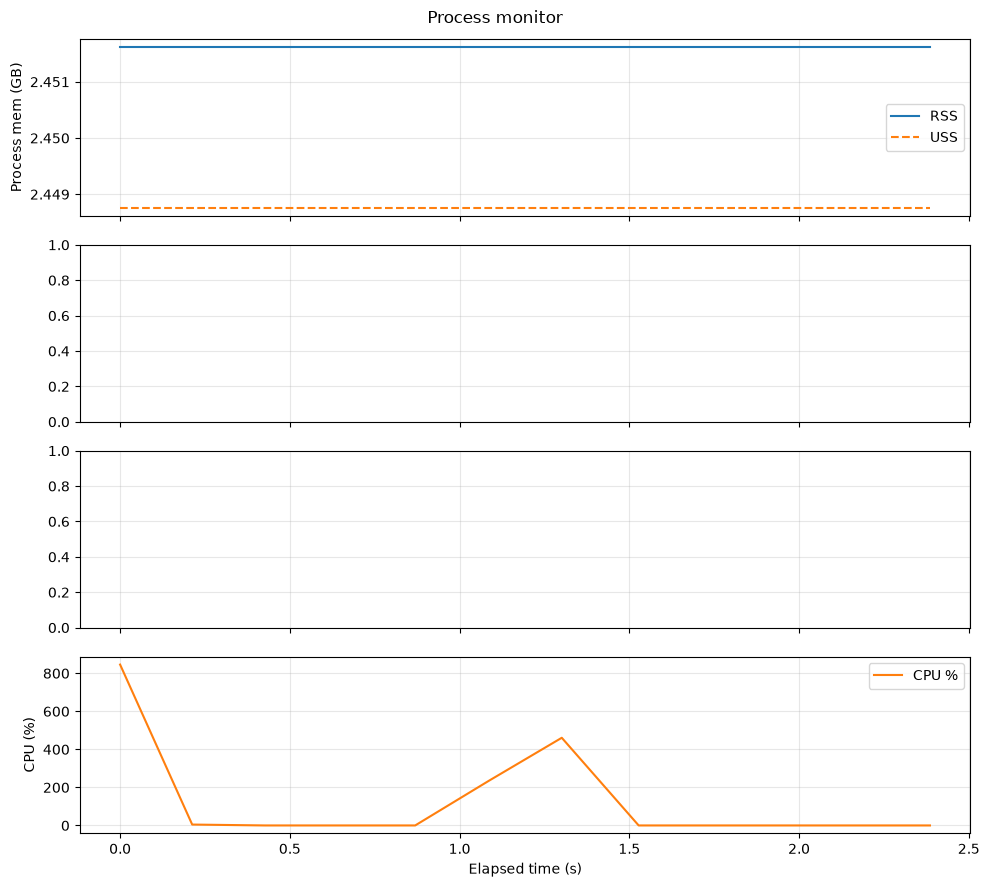

In [6]:
fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)

# 1. Process memory (rss/uss)
axes[0].plot(df["t_elapsed"], df["rss_gb"], label="RSS")
axes[0].plot(df["t_elapsed"], df["uss_gb"], label="USS", linestyle="--")
axes[0].set_ylabel("Process mem (GB)")
axes[0].legend()

# # 2. VMS (separate because it's much larger)
# axes[1].plot(df["t_elapsed"], df["vms_gb"], color="tab:purple", label="VMS")
# axes[1].set_ylabel("VMS (GB)")
# axes[1].legend()

# # 3. System available memory + swap
# axes[2].plot(df["t_elapsed"], df["sys_avail_gb"], color="tab:green", label="Sys available")
# axes[2].plot(df["t_elapsed"], df["swap_used_gb"], color="tab:red", label="Swap used")
# axes[2].set_ylabel("System (GB)")
# axes[2].legend()

# 4. CPU
axes[3].plot(df["t_elapsed"], df["cpu_pct"], color="tab:orange", label="CPU %")
axes[3].set_ylabel("CPU (%)")
axes[3].set_xlabel("Elapsed time (s)")
axes[3].legend()

for ax in axes:
    ax.grid(alpha=0.3)

fig.suptitle("Process monitor")
fig.tight_layout()
plt.show()